In [2]:
import json
import os
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from pathlib import Path

# =========================================================
# WORKING DIRECTORY SETUP
# =========================================================
current_dir = Path.cwd()
if current_dir.name == "notebooks":
    os.chdir(current_dir.parent)
    print(f"Changed working directory to: {Path.cwd()}")
else:
    print(f"Working directory is already: {Path.cwd()}")

# =========================================================
# GLOBAL COLOR & STYLE SETTINGS
# =========================================================
sns.set_theme(style="whitegrid")

# Increased font sizes for thesis readability
plt.rcParams.update({
    'font.size': 14,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14
})

LLAMA_COLOR = '#4c72b0'
QWEN_COLOR = '#c44e52'
FIRE_COLOR = '#7f8c8d'
BAR_ALPHA = 0.8
EDGE_COLOR = 'black'

# =========================================================
# DATA LOADING
# =========================================================
fire_path = "data/05_archive/final_fire/fire_report.json"

llama_paths = {
    "Zero-shot": "data/05_archive/final_llama/processed/zero_shot_report.json",
    "Few-shot":  "data/05_archive/final_llama/processed/few_shot_report.json",
    "Entity":    "data/05_archive/final_llama/processed/entity_report.json",
    "Template":  "data/05_archive/final_llama/processed/template_report.json"
}

qwen_paths = {
    "Zero-shot": "data/05_archive/final_qwen/processed/zero_shot_report.json",
    "Few-shot":  "data/05_archive/final_qwen/processed/few_shot_report.json",
    "Entity":    "data/05_archive/final_qwen/processed/entity_report.json",
    "Template":  "data/05_archive/final_qwen/processed/template_report.json"
}

def load_report(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

fire_data = load_report(fire_path)
llama_data = {k: load_report(v) for k, v in llama_paths.items()}
qwen_data = {k: load_report(v) for k, v in qwen_paths.items()}

print("All reports loaded successfully!")

Working directory is already: C:\Users\Matej\Documents\GitHub\MasterThesis\MasterThesis
All reports loaded successfully!


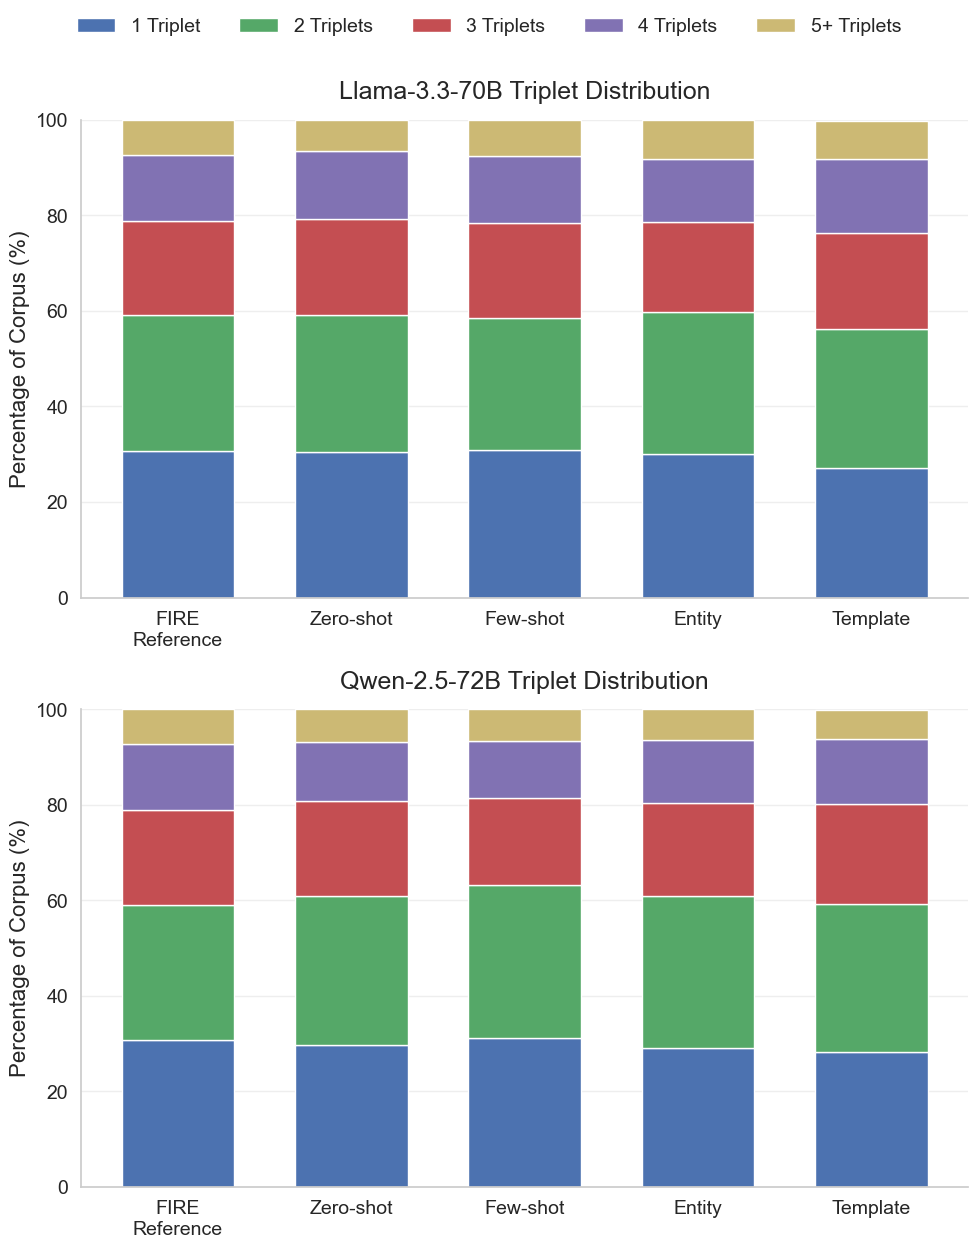

In [3]:
# =========================================================
# TRIPLET DISTRIBUTION ANALYSIS
# =========================================================
triplet_keys = ["1_triplets", "2_triplets", "3_triplets", "4_triplets", "5_triplets"]
labels = ['1 Triplet', '2 Triplets', '3 Triplets', '4 Triplets', '5+ Triplets']

def extract_distribution(model_dict, reference_dict):
    # Extract reference percentages first
    distributions = {key: [reference_dict["Statistical"]["triplet_density"]["percentages"].get(key, 0)] for key in triplet_keys}

    # Append percentages for each generation strategy
    for strategy in ["Zero-shot", "Few-shot", "Entity", "Template"]:
        pcts = model_dict[strategy]["Statistical"]["triplet_density"]["percentages"]
        for key in triplet_keys:
            distributions[key].append(pcts.get(key, 0))

    return distributions

llama_dist = extract_distribution(llama_data, fire_data)
qwen_dist = extract_distribution(qwen_data, fire_data)

x_labels = ["FIRE\nReference", "Zero-shot", "Few-shot", "Entity", "Template"]
colors = ['#4c72b0', '#55a868', '#c44e52', '#8172b3', '#ccb974']

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 12))

def plot_stacked(ax, dist_data, title):
    bottom = np.zeros(len(x_labels))
    for idx, key in enumerate(triplet_keys):
        values = dist_data[key]
        ax.bar(x_labels, values, bottom=bottom, label=labels[idx], color=colors[idx], edgecolor='white', width=0.65)
        bottom += np.array(values)

    ax.set_title(title, pad=15)
    ax.set_ylabel('Percentage of Corpus (%)')
    ax.set_ylim(0, 100)
    ax.set_axisbelow(True)
    ax.yaxis.grid(True, color='#eeeeee')

# Render subplots
plot_stacked(ax1, llama_dist, 'Llama-3.3-70B Triplet Distribution')
plot_stacked(ax2, qwen_dist, 'Qwen-2.5-72B Triplet Distribution')

# Position a shared legend at the top
handles, legend_labels = ax1.get_legend_handles_labels()
fig.legend(handles, legend_labels, loc='upper center', bbox_to_anchor=(0.5, 1.05), ncol=5, frameon=False)

sns.despine()
plt.tight_layout()

out_dir = Path("output/presentation/triplet_complexity")
out_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(out_dir / 'triplet_density_stacked.png', dpi=300, bbox_inches='tight')
plt.show()

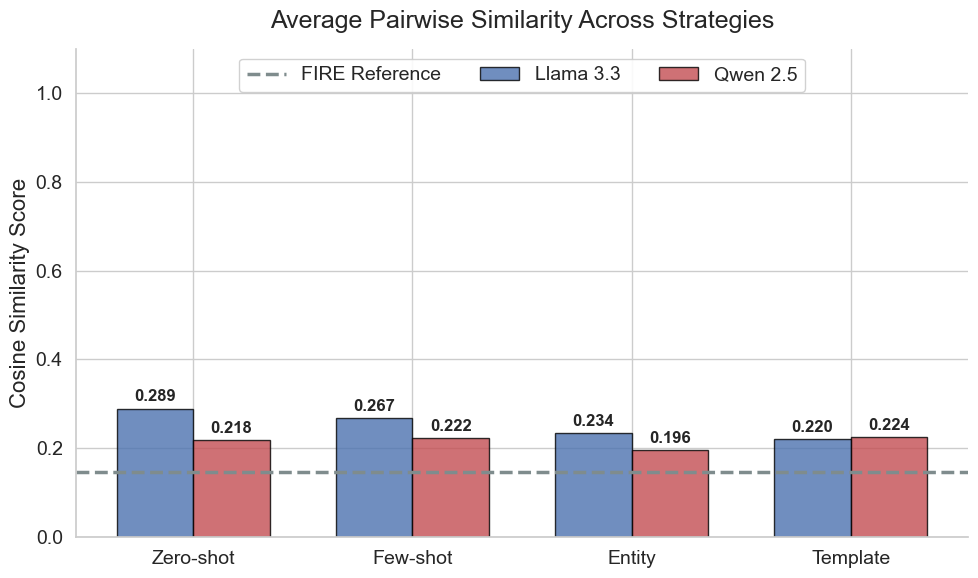

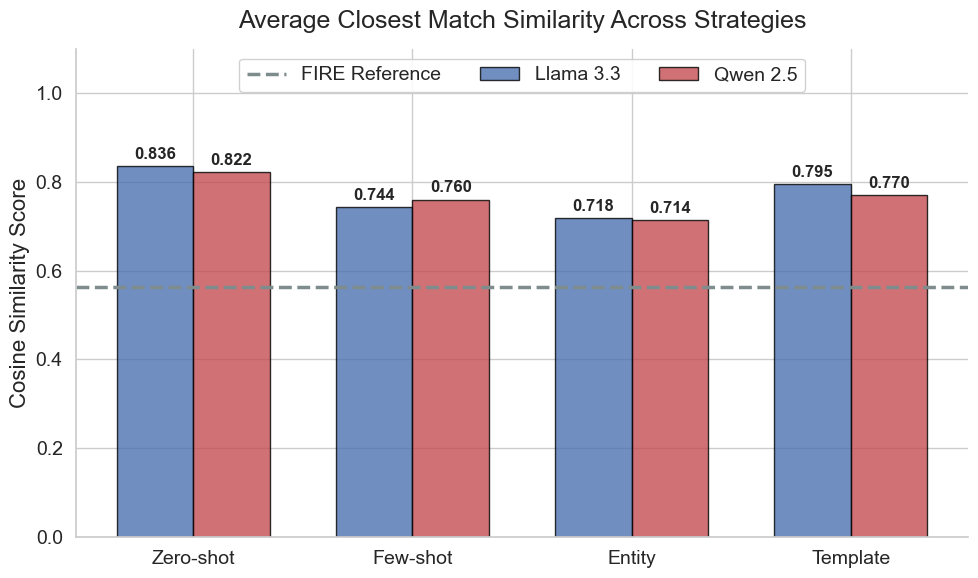

In [4]:
# =========================================================
# DIVERSITY: SEMANTIC SIMILARITY
# =========================================================
strategies = list(llama_paths.keys())
x = np.arange(len(strategies))
width = 0.35

# Extract Pairwise Similarity
fire_pairwise = fire_data["Diversity"]["pairwise_similarity"]["avg_pairwise_sim"]
llama_pairwise = [llama_data[s]["Diversity"]["pairwise_similarity"]["avg_pairwise_sim"] for s in strategies]
qwen_pairwise = [qwen_data[s]["Diversity"]["pairwise_similarity"]["avg_pairwise_sim"] for s in strategies]

# Extract Closest Match Similarity
fire_closest = fire_data["Diversity"]["closest_match_similarity"]["avg_closest_match"]
llama_closest = [llama_data[s]["Diversity"]["closest_match_similarity"]["avg_closest_match"] for s in strategies]
qwen_closest = [qwen_data[s]["Diversity"]["closest_match_similarity"]["avg_closest_match"] for s in strategies]

output_dir = Path("output/presentation/diversity")
output_dir.mkdir(parents=True, exist_ok=True)

# --- Plot A: Average Pairwise Similarity ---
fig1, ax1 = plt.subplots(figsize=(10, 6))

rects1_llama = ax1.bar(x - width/2, llama_pairwise, width, label='Llama 3.3',
                       color=LLAMA_COLOR, alpha=BAR_ALPHA, edgecolor=EDGE_COLOR)
rects1_qwen = ax1.bar(x + width/2, qwen_pairwise, width, label='Qwen 2.5',
                      color=QWEN_COLOR, alpha=BAR_ALPHA, edgecolor=EDGE_COLOR)

ax1.axhline(fire_pairwise, color=FIRE_COLOR, linestyle='--', linewidth=2.5, label='FIRE Reference')
ax1.set_ylabel('Cosine Similarity Score')
ax1.set_title('Average Pairwise Similarity Across Strategies', pad=15)
ax1.set_xticks(x)
ax1.set_xticklabels(strategies)
ax1.set_ylim(0, 1.1)
ax1.legend(loc='upper center', ncol=3, framealpha=0.9)

ax1.bar_label(rects1_llama, padding=3, fmt='%.3f', fontsize=12, fontweight='bold')
ax1.bar_label(rects1_qwen, padding=3, fmt='%.3f', fontsize=12, fontweight='bold')

sns.despine()
plt.tight_layout()
plt.savefig(output_dir / "pairwise_similarity_presentation.png", dpi=300, bbox_inches='tight')
plt.show()

# --- Plot B: Average Closest Match Similarity ---
fig2, ax2 = plt.subplots(figsize=(10, 6))

rects2_llama = ax2.bar(x - width/2, llama_closest, width, label='Llama 3.3',
                       color=LLAMA_COLOR, alpha=BAR_ALPHA, edgecolor=EDGE_COLOR)
rects2_qwen = ax2.bar(x + width/2, qwen_closest, width, label='Qwen 2.5',
                      color=QWEN_COLOR, alpha=BAR_ALPHA, edgecolor=EDGE_COLOR)

ax2.axhline(fire_closest, color=FIRE_COLOR, linestyle='--', linewidth=2.5, label='FIRE Reference')
ax2.set_ylabel('Cosine Similarity Score')
ax2.set_title('Average Closest Match Similarity Across Strategies', pad=15)
ax2.set_xticks(x)
ax2.set_xticklabels(strategies)
ax2.set_ylim(0, 1.1)
ax2.legend(loc='upper center', ncol=3, framealpha=0.9)

ax2.bar_label(rects2_llama, padding=3, fmt='%.3f', fontsize=12, fontweight='bold')
ax2.bar_label(rects2_qwen, padding=3, fmt='%.3f', fontsize=12, fontweight='bold')

sns.despine()
plt.tight_layout()
plt.savefig(output_dir / "closest_match_similarity_presentation.png", dpi=300, bbox_inches='tight')
plt.show()

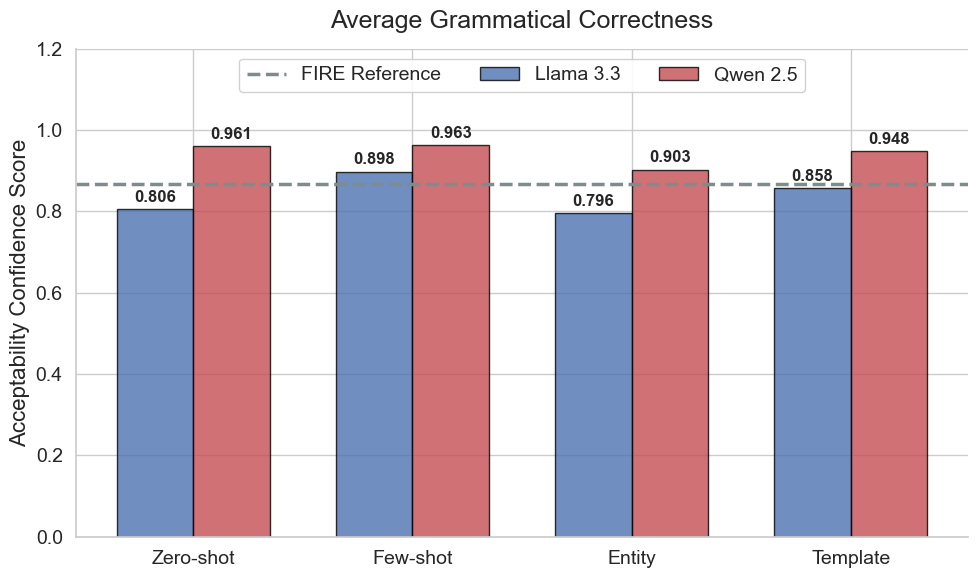

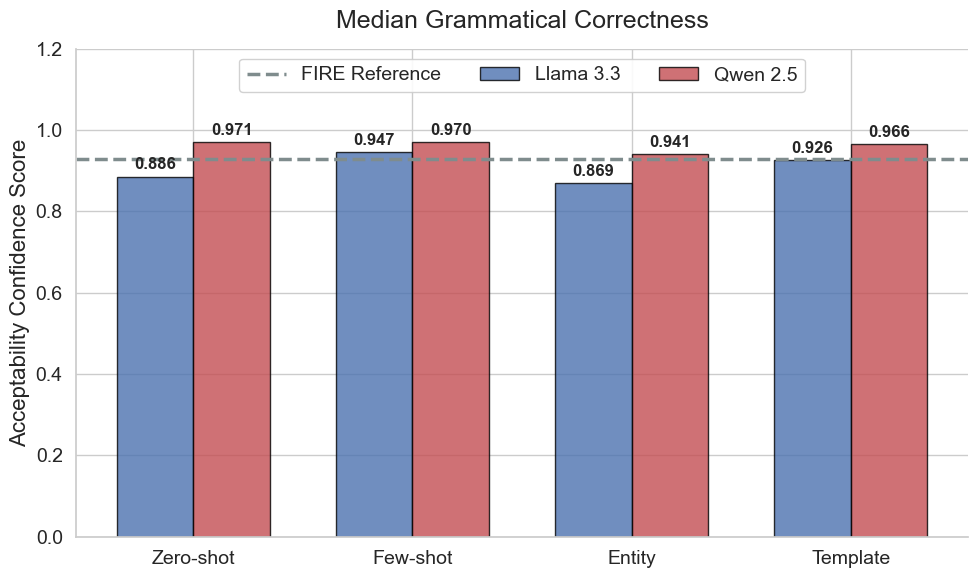

In [5]:
# =========================================================
# GRAMMATICAL CORRECTNESS
# =========================================================
strategies = list(llama_paths.keys())
x = np.arange(len(strategies))
width = 0.35

# Safe extraction for FIRE reference data
fire_grammar = fire_data.get("Grammar", {}).get("metrics", {})
fire_avg = fire_grammar.get("avg_score", None)
fire_median = fire_grammar.get("median_score", None)

# Extract LLM Grammar Scores
llama_avg = [llama_data[s]["Grammar"]["metrics"]["avg_score"] for s in strategies]
llama_median = [llama_data[s]["Grammar"]["metrics"]["median_score"] for s in strategies]
qwen_avg = [qwen_data[s]["Grammar"]["metrics"]["avg_score"] for s in strategies]
qwen_median = [qwen_data[s]["Grammar"]["metrics"]["median_score"] for s in strategies]

output_dir = Path("output/presentation/grammar")
output_dir.mkdir(parents=True, exist_ok=True)

# --- Plot A: Average Grammatical Correctness ---
fig1, ax1 = plt.subplots(figsize=(10, 6))

rects1_llama = ax1.bar(x - width/2, llama_avg, width, label='Llama 3.3',
                       color=LLAMA_COLOR, alpha=BAR_ALPHA, edgecolor=EDGE_COLOR)
rects1_qwen = ax1.bar(x + width/2, qwen_avg, width, label='Qwen 2.5',
                      color=QWEN_COLOR, alpha=BAR_ALPHA, edgecolor=EDGE_COLOR)

if fire_avg is not None:
    ax1.axhline(fire_avg, color=FIRE_COLOR, linestyle='--', linewidth=2.5, label='FIRE Reference')

ax1.set_ylabel('Acceptability Confidence Score')
ax1.set_title('Average Grammatical Correctness', pad=15)
ax1.set_xticks(x)
ax1.set_xticklabels(strategies)
ax1.set_ylim(0, 1.2)
ax1.legend(loc='upper center', ncol=3 if fire_avg is not None else 2, framealpha=0.9)

ax1.bar_label(rects1_llama, padding=3, fmt='%.3f', fontsize=12, fontweight='bold')
ax1.bar_label(rects1_qwen, padding=3, fmt='%.3f', fontsize=12, fontweight='bold')

sns.despine()
plt.tight_layout()
plt.savefig(output_dir / "average_grammar_presentation.png", dpi=300, bbox_inches='tight')
plt.show()

# --- Plot B: Median Grammatical Correctness ---
fig2, ax2 = plt.subplots(figsize=(10, 6))

rects2_llama = ax2.bar(x - width/2, llama_median, width, label='Llama 3.3',
                       color=LLAMA_COLOR, alpha=BAR_ALPHA, edgecolor=EDGE_COLOR)
rects2_qwen = ax2.bar(x + width/2, qwen_median, width, label='Qwen 2.5',
                      color=QWEN_COLOR, alpha=BAR_ALPHA, edgecolor=EDGE_COLOR)

if fire_median is not None:
    ax2.axhline(fire_median, color=FIRE_COLOR, linestyle='--', linewidth=2.5, label='FIRE Reference')

ax2.set_ylabel('Acceptability Confidence Score')
ax2.set_title('Median Grammatical Correctness', pad=15)
ax2.set_xticks(x)
ax2.set_xticklabels(strategies)
ax2.set_ylim(0, 1.2)
ax2.legend(loc='upper center', ncol=3 if fire_median is not None else 2, framealpha=0.9)

ax2.bar_label(rects2_llama, padding=3, fmt='%.3f', fontsize=12, fontweight='bold')
ax2.bar_label(rects2_qwen, padding=3, fmt='%.3f', fontsize=12, fontweight='bold')

sns.despine()
plt.tight_layout()
plt.savefig(output_dir / "median_grammar_presentation.png", dpi=300, bbox_inches='tight')
plt.show()

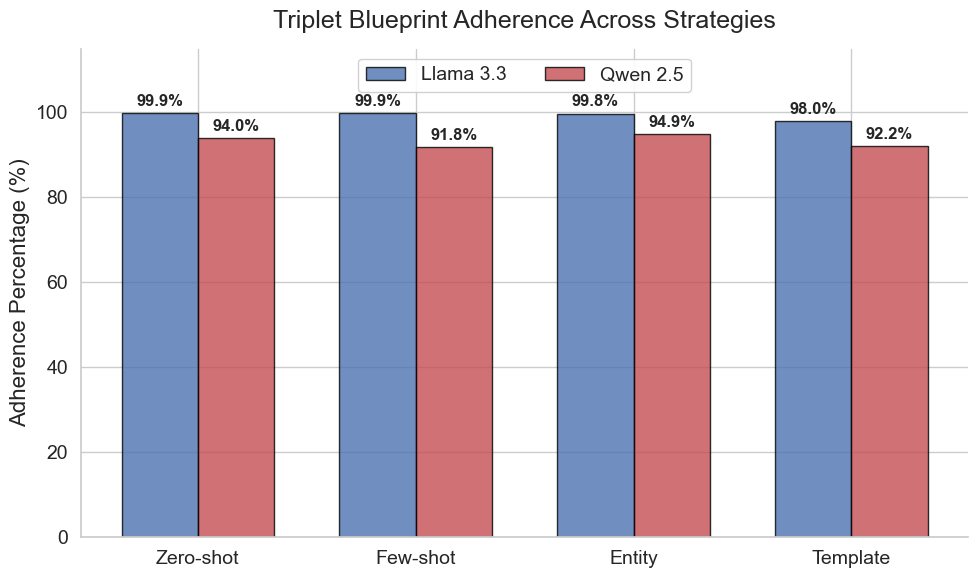

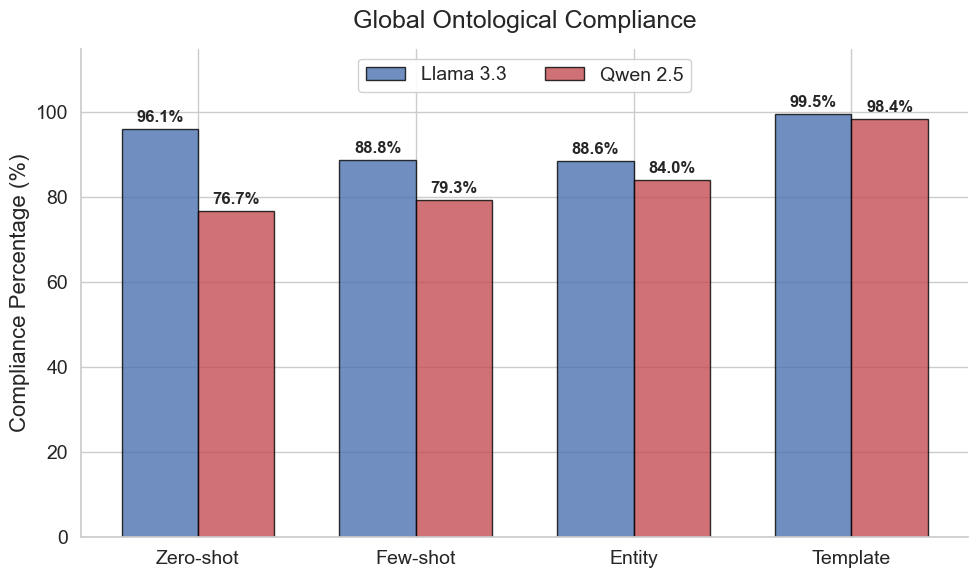

In [8]:
# =========================================================
# GLOBAL ADEQUACY: BLUEPRINT & ONTOLOGY
# =========================================================
strategies = list(llama_paths.keys())
x = np.arange(len(strategies))
width = 0.35

# Extract Blueprint Adherence
llama_blueprint = [llama_data[s]["Adequacy"]["blueprint_adherence"]["triplet_blueprint_adherence"] for s in strategies]
qwen_blueprint = [qwen_data[s]["Adequacy"]["blueprint_adherence"]["triplet_blueprint_adherence"] for s in strategies]

# Extract Ontology Compliance
llama_schema = [llama_data[s]["Adequacy"]["ontology_compliance"]["compliance_percentage"] for s in strategies]
qwen_schema = [qwen_data[s]["Adequacy"]["ontology_compliance"]["compliance_percentage"] for s in strategies]

output_dir = Path("output/presentation/adequacy")
output_dir.mkdir(parents=True, exist_ok=True)

# --- Plot A: Blueprint Adherence ---
fig1, ax1 = plt.subplots(figsize=(10, 6))

rects1_llama = ax1.bar(x - width/2, llama_blueprint, width, label='Llama 3.3',
                       color=LLAMA_COLOR, alpha=BAR_ALPHA, edgecolor=EDGE_COLOR)
rects1_qwen = ax1.bar(x + width/2, qwen_blueprint, width, label='Qwen 2.5',
                      color=QWEN_COLOR, alpha=BAR_ALPHA, edgecolor=EDGE_COLOR)

ax1.set_ylabel('Adherence Percentage (%)')
ax1.set_title('Triplet Blueprint Adherence Across Strategies', pad=15)
ax1.set_xticks(x)
ax1.set_xticklabels(strategies)
ax1.set_ylim(0, 115)
ax1.legend(loc='upper center', ncol=2, framealpha=0.9)

ax1.bar_label(rects1_llama, padding=3, fmt='%.1f%%', fontsize=12, fontweight='bold')
ax1.bar_label(rects1_qwen, padding=3, fmt='%.1f%%', fontsize=12, fontweight='bold')

sns.despine()
plt.tight_layout()
plt.savefig(output_dir / "blueprint_adherence_presentation.png", dpi=300, bbox_inches='tight')
plt.show()

# --- Plot B: Ontology Compliance ---
fig2, ax2 = plt.subplots(figsize=(10, 6))

rects2_llama = ax2.bar(x - width/2, llama_schema, width, label='Llama 3.3',
                       color=LLAMA_COLOR, alpha=BAR_ALPHA, edgecolor=EDGE_COLOR)
rects2_qwen = ax2.bar(x + width/2, qwen_schema, width, label='Qwen 2.5',
                      color=QWEN_COLOR, alpha=BAR_ALPHA, edgecolor=EDGE_COLOR)

ax2.set_ylabel('Compliance Percentage (%)')
ax2.set_title('Global Ontological Compliance', pad=15)
ax2.set_xticks(x)
ax2.set_xticklabels(strategies)
ax2.set_ylim(0, 115)
ax2.legend(loc='upper center', ncol=2, framealpha=0.9)

ax2.bar_label(rects2_llama, padding=3, fmt='%.1f%%', fontsize=12, fontweight='bold')
ax2.bar_label(rects2_qwen, padding=3, fmt='%.1f%%', fontsize=12, fontweight='bold')

sns.despine()
plt.tight_layout()
plt.savefig(output_dir / "ontology_compliance_presentation.png", dpi=300, bbox_inches='tight')
plt.show()

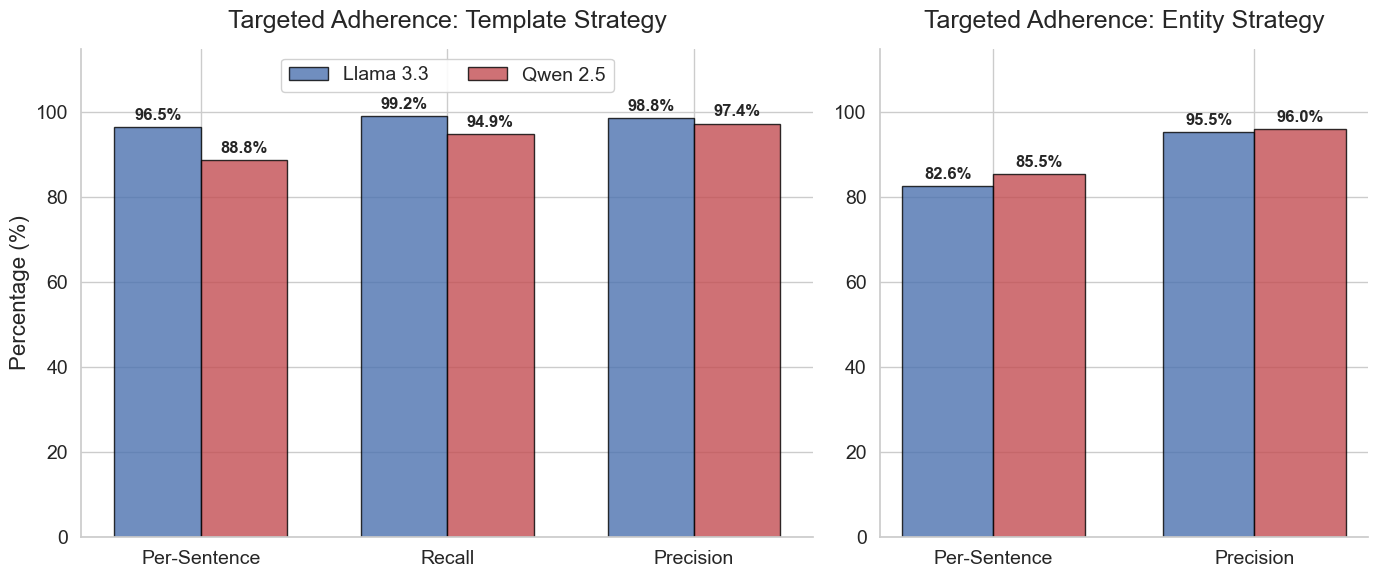

In [7]:
# =========================================================
# TARGETED ADEQUACY: TEMPLATE & ENTITY STRATEGIES
# =========================================================

# Extract Template Strategy Metrics
template_metrics = ["Per-Sentence", "Recall", "Precision"]
llama_template = [
    llama_data["Template"]["Adequacy"]["template_adherence"]["per_sentence_percentage"],
    llama_data["Template"]["Adequacy"]["template_adherence"]["per_triplet_recall_percentage"],
    llama_data["Template"]["Adequacy"]["template_adherence"]["per_triplet_precision_percentage"]
]
qwen_template = [
    qwen_data["Template"]["Adequacy"]["template_adherence"]["per_sentence_percentage"],
    qwen_data["Template"]["Adequacy"]["template_adherence"]["per_triplet_recall_percentage"],
    qwen_data["Template"]["Adequacy"]["template_adherence"]["per_triplet_precision_percentage"]
]

# Extract Entity Strategy Metrics
entity_metrics = ["Per-Sentence", "Precision"]
llama_entity = [
    llama_data["Entity"]["Adequacy"]["entity_adherence"]["per_sentence_percentage"],
    llama_data["Entity"]["Adequacy"]["entity_adherence"]["per_entity_precision_percentage"]
]
qwen_entity = [
    qwen_data["Entity"]["Adequacy"]["entity_adherence"]["per_sentence_percentage"],
    qwen_data["Entity"]["Adequacy"]["entity_adherence"]["per_entity_precision_percentage"]
]

# Setup side-by-side plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={'width_ratios': [3, 2]})
width = 0.35

# --- Axis 1: Template Strategy ---
x_temp = np.arange(len(template_metrics))
rects_t_llama = ax1.bar(x_temp - width/2, llama_template, width, label='Llama 3.3',
                        color=LLAMA_COLOR, alpha=BAR_ALPHA, edgecolor=EDGE_COLOR)
rects_t_qwen = ax1.bar(x_temp + width/2, qwen_template, width, label='Qwen 2.5',
                       color=QWEN_COLOR, alpha=BAR_ALPHA, edgecolor=EDGE_COLOR)

ax1.set_title('Targeted Adherence: Template Strategy', pad=15)
ax1.set_ylabel('Percentage (%)')
ax1.set_xticks(x_temp)
ax1.set_xticklabels(template_metrics)
ax1.set_ylim(0, 115)
ax1.legend(loc='upper center', ncol=2, framealpha=0.9)
ax1.bar_label(rects_t_llama, padding=3, fmt='%.1f%%', fontsize=12, fontweight='bold')
ax1.bar_label(rects_t_qwen, padding=3, fmt='%.1f%%', fontsize=12, fontweight='bold')

# --- Axis 2: Entity Strategy ---
x_ent = np.arange(len(entity_metrics))
rects_e_llama = ax2.bar(x_ent - width/2, llama_entity, width, label='Llama 3.3',
                        color=LLAMA_COLOR, alpha=BAR_ALPHA, edgecolor=EDGE_COLOR)
rects_e_qwen = ax2.bar(x_ent + width/2, qwen_entity, width, label='Qwen 2.5',
                       color=QWEN_COLOR, alpha=BAR_ALPHA, edgecolor=EDGE_COLOR)

ax2.set_title('Targeted Adherence: Entity Strategy', pad=15)
ax2.set_xticks(x_ent)
ax2.set_xticklabels(entity_metrics)
ax2.set_ylim(0, 115)
ax2.bar_label(rects_e_llama, padding=3, fmt='%.1f%%', fontsize=12, fontweight='bold')
ax2.bar_label(rects_e_qwen, padding=3, fmt='%.1f%%', fontsize=12, fontweight='bold')

sns.despine()
plt.tight_layout()
plt.savefig(output_dir / "targeted_adherence_presentation.png", dpi=300, bbox_inches='tight')
plt.show()